# Сканирование кубического мира: детекция персонажей в Minecraft с FCOS и YOLO

**Цель проекта** — дообучить два детектора объектов, anchor-free модель **FCOS** (фреймворк MMDetection) и **YOLOv8s** (библиотека Ultralytics), распознавать основные классы мобов Minecraft, а затем сравнить модели по качеству (mAP, mAP@0.5) и скорости инференса (FPS), визуально оценить их работу на тестовых изображениях и на видеопотоке.

**Данные** — датасет в формате COCO с 17 классами персонажей:
`bee, chicken, cow, creeper, enderman, fox, frog, ghast, goat, llama, pig, sheep, skeleton, spider, turtle, wolf, zombie`.
Датасет разбит на три выборки: `train`, `valid`, `test`.

**Как организован проект.** Корень проекта — папка `mmdetection/`. Весь код вынесен в `.py`-файлы в корне проекта, а ноутбук только вызывает функции из них и хранит выводы:

| Файл | Назначение |
|---|---|
| `constants.py` | Список классов, типы персонажей, палитра цветов, пути к данным и артефактам |
| `eda.py` | Знакомство с персонажами датасета и исследовательский анализ данных |
| `configs/fcos/fcos_minecraft.py` | Конфигурация дообучения FCOS (MMDetection) |
| `prepare_yolo_dataset.py` | Конвертация разметки COCO → YOLO TXT и создание `data.yaml` |
| `augment_dataset.py` | Офлайн-аугментация изображений с редкими классами (Albumentations) перед обучением |
| `detection_models.py` | Загрузка FCOS и YOLO, единый интерфейс инференса, отрисовка рамок |
| `train_fcos.py` | Запуск обучения FCOS, чтение логов и графики обучения |
| `train_yolo.py` | Запуск обучения YOLOv8, чтение `results.csv` и графики обучения |
| `process_video.py` | Покадровый инференс на видео (`cv2.VideoCapture` → `cv2.VideoWriter`) |
| `evaluate.py` | Метрики mAP / mAP@0.5 обеих моделей на тесте, таблица сравнения с FPS |
| `report.py` | Итоговый PDF-отчёт (класс `PDFReport` на fpdf2) |

**Этапы работы:**

0. Изучение специфики Minecraft.
1. Подготовка к выполнению проекта.
2. Исследовательский анализ (EDA) и работа с данными.
3. Настройка конфигурации моделей.
4. Обучение моделей.
5. Инференс моделей.
6. Сравнение стандартных метрик.
7. Анализ и выводы.

## Подготовка рабочей папки

Все пути в коде проекта относительные и отсчитываются от корня проекта — папки `mmdetection/`. Jupyter делает рабочей папкой ядра ту папку, в которой лежит ноутбук, поэтому достаточно запускать `notebook.ipynb` из `mmdetection/` (в окружении `clean_venv`, где установлены PyTorch, MMCV и MMDetection). Проверим, что это так.

In [1]:
import os
import sys

print('Интерпретатор:', sys.executable)
print('Рабочая папка:', os.getcwd())

# Если ноутбук открыт не из папки проекта, модули проекта не найдутся
if not os.path.exists('constants.py'):
    raise FileNotFoundError('Запустите ноутбук из папки mmdetection/ - в ней лежат модули проекта')

Интерпретатор: F:\yandex_practicum_project_2\clean_venv\Scripts\python.exe
Рабочая папка: F:\yandex_practicum_project_2\mmdetection


## Этап 0. Изучение специфики Minecraft

Персонажи (мобы) Minecraft по поведению делятся на три типа — см. перечень мобов на [официальной вики игры](https://minecraft.fandom.com/ru/wiki/%D0%9C%D0%BE%D0%B1%D1%8B):

- **дружелюбные** (пассивные) — никогда не нападают на игрока (свинья, корова, овца, курица…);
- **нейтральные** — нападают только в ответ или при определённых условиях (волк, лама, пчела, эндермен, паук…);
- **враждебные** — нападают первыми (зомби, скелет, крипер, гаст).

Детектору тип поведения не нужен — он учится только по внешнему виду. Но он нужен нам: понимая, кто есть кто и где обычно встречается, проще визуально проверять корректность детекций (например, на видео враждебные мобы чаще ожидаемы ночью, в пещерах и в Незере).

Ниже собран справочник по 17 классам датасета: как выглядит персонаж и на что обращать внимание при оценке детектора.

| Класс | Название | Тип | Как выглядит | Что важно для детектора |
|---|---|---|---|---|
| `bee` | Пчела | нейтральный | Маленький жёлто-чёрный полосатый моб с полупрозрачными крыльями, летает у цветов и ульев | Очень мелкий объект — легко пропустить |
| `chicken` | Курица | дружелюбный | Небольшая, белая, с красной бородкой и жёлтым клювом | Мелкий объект; белая, как овца/коза |
| `cow` | Корова | дружелюбный | Крупная чёрно-белая пятнистая, четвероногая, с рогами | Пятнистый окрас хорошо различим |
| `creeper` | Крипер | враждебный | Зелёный вытянутый «столбик» на четырёх коротких ногах, чёрное «лицо» | Зелёный на фоне травы и листвы — низкий контраст |
| `enderman` | Эндермен | нейтральный | Очень высокий, чёрный, с длинными руками и ногами, фиолетовые глаза и частицы | Тёмный, обычно встречается ночью — плохо виден |
| `fox` | Лиса | дружелюбный | Рыжая с белой грудью и хвостом; в снежных биомах — белая | Белая лиса легко путается с волком |
| `frog` | Лягушка | дружелюбный | Маленькая, приземистая, оранжевая/белая/зелёная в зависимости от биома | Мелкий объект, три окраса |
| `ghast` | Гаст | враждебный | Огромный белый куб с щупальцами, парит в воздухе в Незере | Необычный фон (Незер), нет аналогов среди классов |
| `goat` | Козёл | нейтральный | Светлая, с рогами, встречается в горах | Похожа на овцу и ламу |
| `llama` | Лама | нейтральный | Высокая, с длинной шеей; окрас кремовый, белый, коричневый или серый; может нести ковёр | Четыре окраса; похожа на козу/овцу |
| `pig` | Свинья | дружелюбный | Розовая, приземистая, четвероногая | Розовый цвет — хорошо различима |
| `sheep` | Овца | дружелюбный | Белая шерсть (может быть окрашена в любой цвет), после стрижки выглядит иначе | Сильная вариативность цвета |
| `skeleton` | Скелет | враждебный | Серо-белый гуманоид с луком | Тот же силуэт, что у зомби |
| `spider` | Паук | нейтральный | Чёрный, широкий и низкий, восемь ног, красные глаза | Тёмный, обычно ночью или в пещерах |
| `turtle` | Черепаха | дружелюбный | Зелёная, плоская, на пляжах и в воде | Мелкая, низкая; зелёная на песке/траве |
| `wolf` | Волк | нейтральный | Серо-белый, похож на собаку; приручённый — с ошейником | Похож на белую лису |
| `zombie` | Зомби | враждебный | Зелёный гуманоид в синей футболке и штанах, руки вытянуты вперёд | Тот же силуэт, что у скелета |

Посмотрим, как эти персонажи выглядят в самом датасете: по одному примеру каждого класса из обучающей выборки. Цвет подписи соответствует типу персонажа: зелёный — дружелюбный, оранжевый — нейтральный, красный — враждебный.

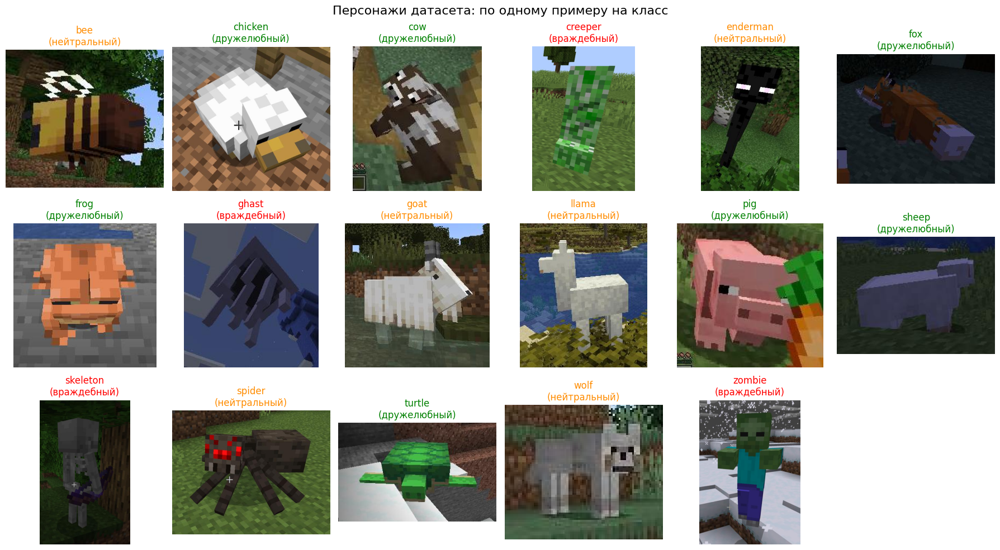

In [2]:
import os

from constants import ANN_FILES, IMG_DIRS, EDA_DIR
from eda import show_class_examples

show_class_examples(
    ann_file=ANN_FILES['train'],
    img_dir=IMG_DIRS['train'],
    save_path=os.path.join(EDA_DIR, 'mob_classes.png')
)

**Выводы этапа 0.** Уже по примерам видно, где детекторам будет сложно — эти наблюдения пригодятся при анализе ошибок моделей:

- **Похожие силуэты.** `skeleton` и `zombie` — гуманоиды одинакового роста, различаются только цветом; `sheep`, `goat` и `llama` — светлые четвероногие; `wolf` и `fox` различаются в основном окрасом. Ошибки классификации ожидаемы именно внутри этих групп.
- **Мелкие объекты.** `bee`, `chicken`, `frog`, `turtle` малы сами по себе и в кадре часто занимают несколько десятков пикселей — сложный случай для одностадийных детекторов (см. сравнение моделей в уроках).
- **Условия съёмки.** `enderman` и `spider` тёмные и встречаются ночью или в пещерах — низкий контраст с фоном; `ghast` живёт в Незере и снят на непохожем на остальные фоне.
- **Вариативность окраса.** `sheep` может быть любого цвета и стриженой, у `llama` четыре окраса, у `fox` — два. Модели придётся выучить класс по форме, а не по цвету.

## Этап 1. Подготовка к выполнению проекта

### Структура проекта

Корень проекта — клон репозитория MMDetection (папка `mmdetection/`), рядом с ним лежит виртуальное окружение `clean_venv/` (так же, как в уроке об установке MMDetection):

```
yandex_practicum_project_2/
├── clean_venv/                          # виртуальное окружение (Python 3.10)
└── mmdetection/                         # корень проекта
    ├── configs/fcos/fcos_minecraft.py   # конфиг дообучения FCOS (этап 3)
    ├── checkpoints/                     # предобученные веса FCOS с COCO
    ├── datasets/minecraft/              # датасет (в репозиторий не загружается)
    │   ├── images/{train,valid,test}/   # изображения - одна копия для обеих моделей
    │   ├── annotations/{train,valid,test}/annotations.json   # COCO-разметка для FCOS
    │   ├── labels/{train,valid,test}/   # YOLO-разметка (создаётся на этапе 3)
    │   ├── data.yaml                    # описание датасета для YOLO (этап 3)
    │   └── video.mp4                    # видео для инференса
    ├── artifacts/                       # результаты работы
    │   ├── eda/                         # графики анализа данных
    │   ├── fcos/                        # логи и веса FCOS
    │   ├── yolo/                        # логи и веса YOLO
    │   ├── inference/fcos/, yolo/       # примеры детекций на тестовых изображениях
    │   ├── metrics/                     # таблица сравнения метрик
    │   └── videos/                      # видео с детекциями
    ├── constants.py, eda.py, ...        # код проекта (.py-файлы)
    ├── notebook.ipynb                   # этот ноутбук
    └── README.md                        # описание проекта и результатов
```

Датасет распакован в `datasets/minecraft/`: изображения выборок — в `images/<выборка>/`, файлы разметки `annotations.json` — в `annotations/<выборка>/` (по подпапке на выборку, потому что все три файла называются одинаково). Изображения хранятся в одном экземпляре и используются обеими моделями: FCOS читает COCO-разметку из `annotations/`, YOLO — текстовую из `labels/` (Ultralytics находит её, заменяя `images/` на `labels/` в пути к изображению). Выборка для валидации называется `valid` (так её экспортировал Roboflow). Видео для инференса лежит в `datasets/minecraft/video.mp4`.

**Правила работы:** весь код обучения, инференса и анализа — в `.py`-файлах в корне проекта; ноутбук только вызывает функции из них, хранит выводы ячеек и текстовые выводы; ячейки выполняются строго по порядку.

### Окружение

Используется рабочая комбинация версий из урока об установке MMDetection и библиотеки из уроков о YOLO:

| Пакет | Версия | Зачем |
|---|---|---|
| Python | 3.10 | — |
| torch / torchvision | 2.0.0+cu118 / 0.15.1+cu118 | обучение и инференс на GPU |
| mmengine / mmcv / mmdet | 0.10.7 / 2.1.0 / 3.3.0 (из исходников, `pip install -e .`) | FCOS |
| numpy | 1.26.4 | требование MMDetection |
| ultralytics | 8.0.196 | YOLOv8 |
| opencv-python, matplotlib, pandas, seaborn 0.13.2 | — | обработка изображений, графики, таблицы |
| fpdf2 2.7.6 | — | PDF-отчёт (этап 7) |
| notebook, ipykernel | — | Jupyter |

Команды установки (Windows, PowerShell; выполняются один раз):

```bash
py -3.10 -m venv clean_venv
.\clean_venv\Scripts\activate
python -m pip install pip==21.2.3
python -m pip install torch==2.0.0+cu118 torchvision==0.15.1+cu118 torchaudio==2.0.1 --index-url https://download.pytorch.org/whl/cu118
python -m pip install -U openmim
python -m pip install "mmengine==0.10.7"
python -m mim install "mmcv==2.1.0"
git clone https://github.com/open-mmlab/mmdetection.git
cd mmdetection
python -m pip install -v -e . --no-build-isolation
python -m pip install numpy==1.26.4
python -m pip install ultralytics==8.0.196 seaborn==0.13.2 fpdf2==2.7.6 notebook ipykernel
```

На учебной ВМ (Ubuntu, NVIDIA Tesla T4 16 ГБ, 4 ядра, 16 ГБ ОЗУ, Python 3.10) команды те же, отличается только создание и активация окружения:

```bash
python3.10 -m venv clean_venv
source clean_venv/bin/activate
# далее - те же pip/mim-команды, что и выше
```

Проверим, что ключевые библиотеки установлены и видеокарта доступна.

In [3]:
import torch
import torchvision
import mmcv
import mmengine
import mmdet
import cv2
import numpy as np

print('torch:', torch.__version__, '| torchvision:', torchvision.__version__)
print('CUDA доступна:', torch.cuda.is_available(),
      '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'GPU не найдена')
print('mmengine:', mmengine.__version__, '| mmcv:', mmcv.__version__, '| mmdet:', mmdet.__version__)
print('numpy:', np.__version__, '| opencv:', cv2.__version__)

torch: 2.0.0+cu118 | torchvision: 0.15.1+cu118
CUDA доступна: True | NVIDIA GeForce RTX 4060 Ti
mmengine: 0.10.7 | mmcv: 2.1.0 | mmdet: 3.3.0
numpy: 1.26.4 | opencv: 4.11.0


## Этап 2. Исследовательский анализ (EDA) и работа с данными

Все проверки и графики реализованы в модуле `eda.py`. Здесь они вызываются по порядку: структура папок → корректность JSON → соответствие изображений и разметки → распределение классов → размеры объектов → пример разметки.

### Структура датасета

По заданию датасет должен быть в формате COCO и делиться на `train / val / test`. Проверим, что все папки с изображениями, файлы разметки и видео на месте.

In [4]:
import os

from constants import SPLITS, ANN_FILES, IMG_DIRS, EDA_DIR
from eda import (check_dataset_structure, check_coco_structure, check_images_match_annotations,
                 analyze_class_distribution, analyze_object_sizes, visualize_sample)

check_dataset_structure()

Структура датасета:
  [OK] datasets/minecraft\images\train/ - 2307 изображений
  [OK] datasets/minecraft\annotations\train\annotations.json
  [OK] datasets/minecraft\images\valid/ - 422 изображений
  [OK] datasets/minecraft\annotations\valid\annotations.json
  [OK] datasets/minecraft\images\test/ - 155 изображений
  [OK] datasets/minecraft\annotations\test\annotations.json
  [OK] datasets/minecraft\video.mp4


### Корректность JSON-разметки

Для каждой выборки проверяем, что файл соответствует формату COCO: есть разделы `images`, `annotations`, `categories`; у изображений заданы `id`, `file_name`, `width`, `height`, а `id` уникальны; у аннотаций заданы `id`, `image_id`, `category_id`, `bbox`, ссылки ведут на существующие изображения и категории, рамки имеют положительный размер и не выходят за границы кадра; имена классов совпадают с `CLASSES` из `constants.py`.

In [5]:
for split in SPLITS:
    problems = check_coco_structure(ANN_FILES[split])
    assert not problems, f'В разметке выборки {split} найдены проблемы'

datasets/minecraft\annotations\train\annotations.json: изображений 2307, аннотаций 4029, классов 17
  Структура JSON корректна
datasets/minecraft\annotations\valid\annotations.json: изображений 422, аннотаций 697, классов 17
  Структура JSON корректна
datasets/minecraft\annotations\test\annotations.json: изображений 155, аннотаций 351, классов 17
  Структура JSON корректна


### Соответствие изображений и разметки

Сверяем файлы на диске с записями в `annotations.json` (через множества имён файлов, как при поиске пар «изображение — метка» в уроке): не должно быть файлов без записи, записей без файла и изображений без единой рамки.

In [6]:
for split in SPLITS:
    check_images_match_annotations(ANN_FILES[split], IMG_DIRS[split])

datasets/minecraft\images\train: файлов на диске 2307, записей в JSON 2307, рамок 4029
  Все изображения размечены, лишних файлов и записей нет
datasets/minecraft\images\valid: файлов на диске 422, записей в JSON 422, рамок 697
  Все изображения размечены, лишних файлов и записей нет
datasets/minecraft\images\test: файлов на диске 155, записей в JSON 155, рамок 351
  Все изображения размечены, лишних файлов и записей нет


**Вывод.** Структура всех трёх файлов корректна, количество изображений на диске совпадает с количеством записей в разметке (2307 / 422 / 155), каждое изображение содержит хотя бы одну рамку, лишних файлов и записей нет. Всего 5077 размеченных объектов: 4029 в train, 697 в valid, 351 в test. Разбиение по выборкам неравномерное — 80 % / 15 % / 5 % изображений, тестовая выборка небольшая.

### Распределение классов

Посчитаем количество объектов каждого класса в каждой выборке.

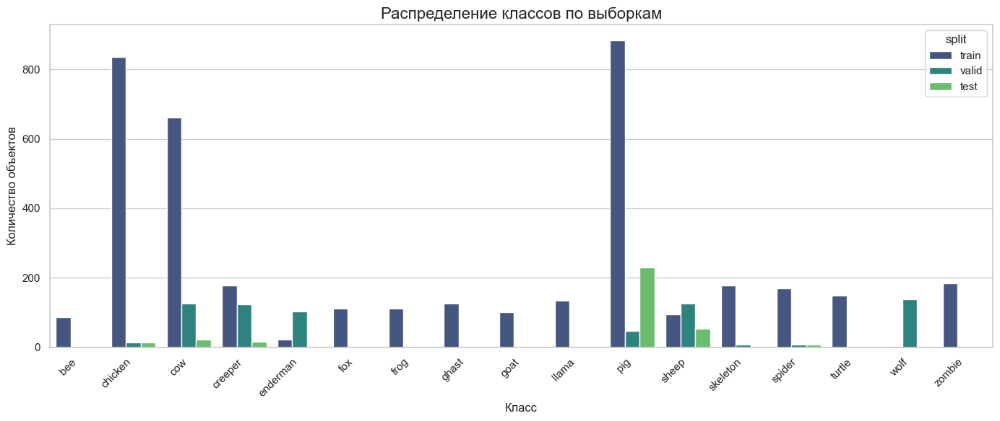

split,train,valid,test,total,train_share_%
class,,,,,
pig,884,48,230,1162,21.9
chicken,835,14,13,862,20.7
cow,661,127,22,810,16.4
creeper,177,123,17,317,4.4
sheep,94,126,53,273,2.3
zombie,184,2,3,189,4.6
skeleton,177,8,4,189,4.4
spider,170,8,7,185,4.2
turtle,149,0,0,149,3.7


In [7]:
class_table = analyze_class_distribution(save_path=os.path.join(EDA_DIR, 'class_distribution.png'))
class_table

**Вывод: дисбаланс есть, и сильный.**

- В обучающей выборке три класса — `pig` (884 объекта, 22 %), `chicken` (835, 21 %) и `cow` (661, 16 %) — дают почти 60 % всех рамок, тогда как у `wolf` всего 4 объекта, у `enderman` — 22, у `bee` — 86. Отношение самого частого класса к самому редкому — 221:1. Модели будут увереннее всего находить свиней, кур и коров, а `wolf` по четырём примерам выучить практически невозможно.
- **Выборки разбиты не по классам.** В `valid` нет семи классов (`bee`, `fox`, `frog`, `ghast`, `goat`, `llama`, `turtle`), в `test` — восьми (те же плюс `wolf`). При этом `wolf` представлен 138 объектами в `valid` при 4 в `train`, а `enderman` — 103 в `valid` при 22 в `train`. Значит:
  - метрики на `test` фактически будут посчитаны по 9 классам (COCO-метрика усредняет AP только по классам, у которых есть объекты в разметке);
  - на `valid` во время обучения AP по `wolf` и `enderman` будет низким у обеих моделей — не из-за архитектуры, а из-за нехватки обучающих примеров;
  - качество на восьми классах, отсутствующих в `test`, можно оценить только визуально — на изображениях из `train` и на видео.
- Как с этим работать. Разбиение оставляем как в исходном датасете: тестовая выборка задана заданием, и на ней обе модели сравниваются в одинаковых условиях, так что сравнение остаётся честным. Дисбаланс компенсируем на уровне данных — как в уроке о подготовке данных: изображения с редкими классами «размножаем» аугментациями перед обучением (скрипт `augment_dataset.py`, этап 3.3), так что у каждого редкого класса становится в 2–8 раз больше примеров, — плюс дообучением с предобученных на COCO весов у обеих моделей; при анализе результатов будем смотреть не только общий mAP, но и AP по классам.

### Размеры изображений и объектов

По заданию для ускорения обучения изображения сжимаются до `img_scale = 512`. Посмотрим, какие разрешения есть в датасете и сколько пикселей будут занимать объекты после такого сжатия: объекты меньше 32 px считаются «мелкими» (по терминологии COCO) и даются одностадийным детекторам тяжелее всего.

In [ ]:
analyze_object_sizes(
    ann_file=ANN_FILES['train'],
    img_scale=640,
    save_path=os.path.join(EDA_DIR, 'object_sizes.png')
)

**Вывод.**

- Изображения имеют шесть разных разрешений — от 640×360 до 2560×1440, с соотношением сторон 16:9 (и близким к нему). Значит, в пайплайне обязательно масштабирование с сохранением пропорций (`keep_ratio=True`), а «квадратный» `img_scale=(640, 640)` на деле даст кадры около 640×360.
- Объекты в основном мелкие: после сжатия до 640 px медианная длинная сторона рамки — около 53 px, а 27 % объектов окажутся меньше 32 px (при 512 px было бы 42 px и 37 %). Поэтому обе модели будем обучать в одном разрешении 640 px: это и честное сравнение архитектур, и меньше потерь на мелких мобах (пчёлы, куры, лягушки вдалеке).
- На большинстве изображений один-два объекта (в среднем 1,75), максимум 18 — сцены в основном простые, без плотных скоплений.

### Пример тестового изображения с разметкой

Отрисуем одно тестовое изображение с истинными рамками и подписями классов — возьмём кадр, на котором сразу шесть объектов двух классов.

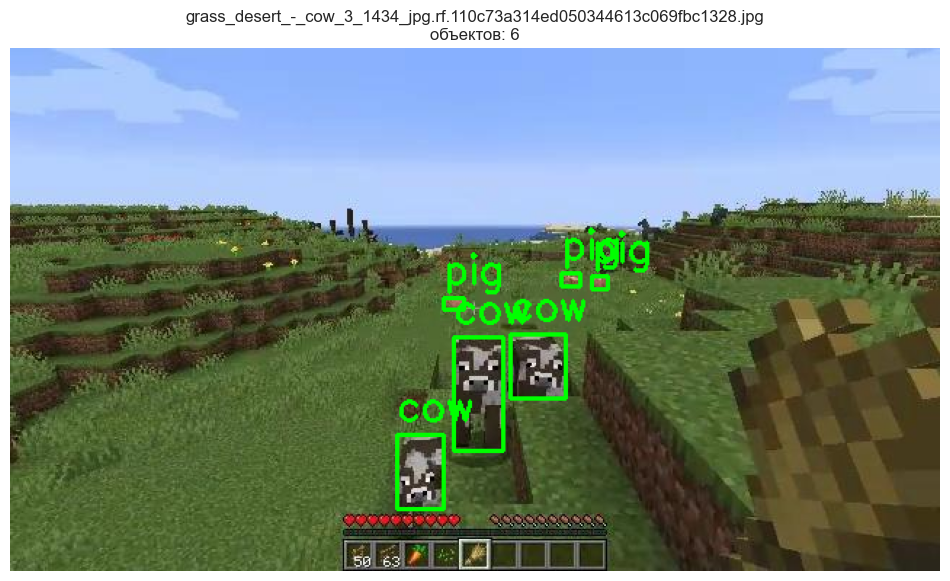

In [9]:
visualize_sample(
    ann_file=ANN_FILES['test'],
    img_dir=IMG_DIRS['test'],
    file_name='grass_desert_-_cow_3_1434_jpg.rf.110c73a314ed050344613c069fbc1328.jpg',
    save_path=os.path.join(EDA_DIR, 'test_sample_gt.png')
)

Разметка выглядит корректно: рамки плотно охватывают персонажей, подписи соответствуют объектам; видно и характерную особенность данных — часть объектов очень мелкая (свиньи на дальнем плане занимают несколько десятков пикселей даже в кадре 1920×1080).

### Аугментация редких классов

Анализ показал сильный дисбаланс: у `wolf` всего 4 рамки, у `enderman` — 22, у `bee` — 86 против 884 у `pig`. Исправим это на уровне данных, как советует урок о подготовке данных: применим аугментации **только к изображениям с редкими классами** и «размножим» их ещё до обучения — тогда обе модели получат одинаковый, уже сбалансированный набор.

Скрипт `augment_dataset.py`:

- берёт изображения обучающей выборки, на которых есть класс из `RARE_CLASS_REPEATS` (`constants.py`: `wolf: 8`, `enderman: 4`, `bee`, `sheep`, `goat`, `fox`, `frog`, `ghast`, `llama`, `turtle`: 2), и делает для каждого `N − 1` копий — вместе с оригиналом класс будет показан `N` раз;
- аугментирует их пайплайном Albumentations из урока: `HorizontalFlip`, `ShiftScaleRotate` (поворот отключён — скриншоты не бывают наклонёнными), `RandomBrightnessContrast`, `HueSaturationValue`, `GaussNoise`, `CoarseDropout`; `bbox_params=A.BboxParams(format='yolo', ...)` пересчитывает рамки вместе с изображением;
- сохраняет копии в `images/train_augmented` + `labels/train_augmented` (для YOLO) и собирает по ним COCO-разметку `annotations/train_augmented/annotations.json` (для FCOS).

Albumentations работает с разметкой в формате YOLO TXT, поэтому сначала конвертируем COCO-разметку в текстовые файлы `datasets/minecraft/labels/<выборка>/` — эти же файлы понадобятся YOLO на этапе 3. Копии воспроизводимы (фиксированный seed), поэтому обе модели обучаются на одном и том же наборе.

In [10]:
import os

from constants import EDA_DIR
from prepare_yolo_dataset import convert_annotations_to_yolo
from augment_dataset import (augment_rare_classes, yolo_to_coco, augmentation_summary,
                             plot_augmentation_effect, show_augmentation_example)

# Разметка в формате YOLO TXT - рабочий формат для Albumentations
convert_annotations_to_yolo()

# Копии изображений с редкими классами: картинки, разметка YOLO и COCO-разметка для FCOS
augmented_boxes = augment_rare_classes()
yolo_to_coco()

augmentation_table = augmentation_summary(augmented_boxes)
augmentation_table

train: разметка YOLO уже подготовлена (2307 файлов)
valid: разметка YOLO уже подготовлена (422 файлов)
test: разметка YOLO уже подготовлена (155 файлов)
Создано 870 аугментированных изображений в datasets/minecraft\images\train_augmented
COCO-разметка для FCOS: datasets/minecraft\annotations\train_augmented\annotations.json (870 изображений, 1296 рамок)


,copies_per_image,boxes_original,boxes_augmented,boxes_total
wolf,7,4,28,32
enderman,3,22,66,88
bee,1,86,86,172
sheep,1,94,96,190
creeper,0,177,17,194
spider,0,170,26,196
goat,1,102,102,204
skeleton,0,177,40,217
frog,1,111,111,222
fox,1,111,119,230


Посмотрим, как изменилось распределение классов в обучающей выборке: сколько рамок каждого класса было и сколько стало.

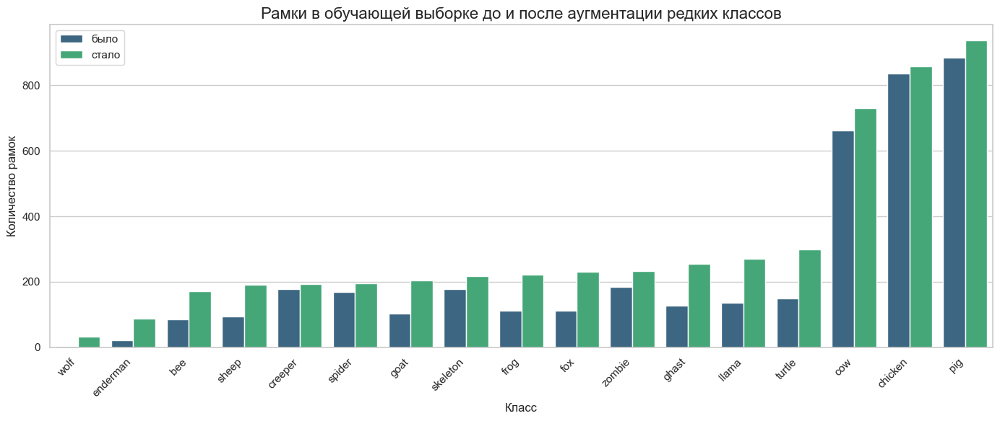

In [11]:
plot_augmentation_effect(augmentation_table, save_path=os.path.join(EDA_DIR, 'augmentation_effect.png'))

Урок требует перед обучением посмотреть на результат аугментаций глазами: объекты не должны исказиться до неузнаваемости, а рамки должны по-прежнему охватывать объекты. Возьмём одно из двух изображений с волками — для него сделано 7 копий.

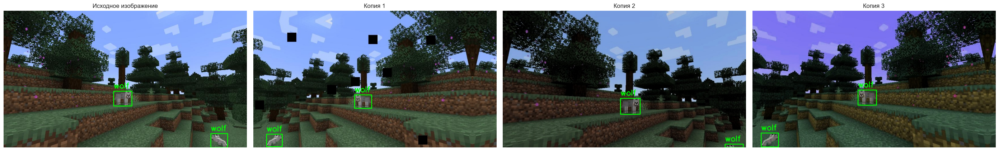

In [12]:
show_augmentation_example('2023-04-03_20_03_14_png.rf.3207007583199cc95d73fdb5378abfca.jpg')

**Вывод.** Аугментации выглядят реалистично: отражение, небольшой сдвиг и масштаб, другая яркость и оттенок, кое-где вырезанные квадраты (имитация перекрытия блоками), а рамки следуют за объектами.

Дисбаланс заметно смягчился: `wolf` вырос с 4 рамок до 32, `enderman` — с 22 до 88, `bee` — с 86 до 172, `sheep` — с 94 до 190, `goat` — с 102 до 204; у остальных редких классов (`fox`, `frog`, `ghast`, `llama`, `turtle`) стало по 220–300 рамок вместо 111–149. Отношение самого частого класса к самому редкому сократилось с 221:1 (`pig` 884 против `wolf` 4) до 29:1 (`pig` 938 против `wolf` 32). Частые классы тоже немного подросли — они попадают в кадр вместе с редкими (например, `cow` 661 → 730): это нормально, важно соотношение, а не абсолютные числа.

Обучающая выборка выросла с 2307 до 3177 изображений (+870 копий). Полностью проблему это не решает: `wolf` по-прежнему снят всего на двух изображениях, и восемь аугментаций не заменят новых сцен — но модель хотя бы увидит этот класс не один раз за эпоху.

### План выполнения проекта

**Как будем решать задачу.**

1. **Данные.** Датасет уже в формате COCO, поэтому для FCOS используем его напрямую через класс `CocoDataset` из MMDetection, передав наши 17 классов в `metainfo`. Для YOLO разметка уже сконвертирована в формат YOLO TXT (`<class_id> <x_center> <y_center> <width> <height>` с нормализованными координатами) в папку `labels/`, осталось описать датасет в `datasets/minecraft/data.yaml`. Редкие классы уже размножены аугментацией (см. выше), обе модели обучаются на одном наборе из 3177 изображений.
2. **FCOS.** Берём стандартную сборку `fcos_r50-caffe_fpn_gn-head_1x_coco.py`, наследуемся от неё в `configs/fcos/fcos_minecraft.py` и переопределяем только нужное: 17 классов в голове, пути к данным, `Resize` до 640 с сохранением пропорций, простые аугментации (`RandomFlip`), 16 эпох, батч 4, сохранение чекпоинта раз в эпоху, смешанная точность (fp16), старт с предобученных на COCO весов из `checkpoints/`. Перед обучением проверяем инференс предобученной модели. Обучение запускаем из ноутбука функцией, которая делает то же, что `tools/train.py` (собирает `Runner` MMEngine по конфигу); логи и веса — в `artifacts/fcos`.
3. **YOLOv8s.** Проверяем инференс предобученной `yolov8s.pt`, затем дообучаем её функцией `train_model` (как в уроке): `model.train(data='datasets/minecraft/data.yaml', epochs=..., imgsz=640, batch=..., seed=42)` с аугментациями YOLO; YOLO учится заметно быстрее, поэтому эпох можно взять больше. Результаты (`results.csv`, `best.pt`) — в `artifacts/yolo`.
4. **Инференс.** Чтобы работать с двумя разными API одинаково, оборачиваем модели в единый интерфейс: функция получает изображение и возвращает `(boxes, labels, scores)`; отрисовка — общая функция `draw_boxes` (рамка, класс, confidence), как в уроке о сравнении моделей. Прогоняем обе модели на тестовых изображениях (по пять примеров в ноутбуке, все — в `artifacts/inference/fcos` и `artifacts/inference/yolo`) и на видео `datasets/minecraft/video.mp4` покадрово (`cv2.VideoCapture` → `cv2.VideoWriter`), результат — в `artifacts/videos`.
5. **Метрики.** mAP и mAP@0.5 на тестовой выборке: для FCOS — через `CocoMetric` MMDetection (`Runner.test()`), для YOLO — через `model.val(split='test')`. FPS — универсальная функция `measure_fps` с прогревом GPU и усреднением по N прогонам. Сводная таблица → `artifacts/metrics/metrics_comparison.csv`.
6. **Отчёт.** Графики обучения (`log.json` FCOS, `results.csv` YOLO), примеры детекций, таблица и диаграммы сравнения → `artifacts/report.pdf` (класс `PDFReport` на fpdf2 из урока об анализе трафика) и краткое описание в `README.md`.

**Из чего будет состоять система.**

| Модуль | Роль |
|---|---|
| `constants.py` | Классы, типы персонажей, палитра, пути к данным и артефактам |
| `eda.py` | Проверка и анализ данных (этот этап) |
| `prepare_yolo_dataset.py` | Конвертация COCO → YOLO TXT, генерация `data.yaml` |
| `configs/fcos/fcos_minecraft.py` | Конфигурация дообучения FCOS |
| `detection_models.py` | Единый интерфейс инференса обеих моделей, `draw_boxes`, `measure_fps` |
| `train_fcos.py`, `train_yolo.py` | Запуск обучения и графики метрик обучения |
| `process_video.py` | Покадровый инференс на видео |
| `evaluate.py` | mAP / mAP@0.5 / FPS обеих моделей, таблица сравнения |
| `report.py` | Сборка PDF-отчёта |

Поток данных: `datasets/minecraft` → (`eda.py`, `prepare_yolo_dataset.py`) → обучение (`train_fcos.py` по конфигу, `train_yolo.py` по `data.yaml`) → веса в `artifacts/fcos`, `artifacts/yolo` → инференс и метрики (`detection_models.py`, `process_video.py`, `evaluate.py`) → `artifacts/inference`, `artifacts/videos`, `artifacts/metrics` → отчёт (`report.py`) → `artifacts/report.pdf`.

## Этап 3. Настройка конфигурации моделей

### 3.1. Конфигурация FCOS

Конфиг дообучения лежит в [`configs/fcos/fcos_minecraft.py`](configs/fcos/fcos_minecraft.py). Он наследуется от стандартной сборки FCOS `fcos_r50-caffe_fpn_gn-head_1x_coco.py` (ResNet-50 + FPN + голова с GroupNorm, расписание 1x) через `_base_` и переопределяет только нужное — так же, как в уроке про MMDetection:

- `metainfo` — 17 классов датасета (в порядке `constants.CLASSES`), они подставляются в `CocoDataset` вместо 80 классов COCO;
- `model` — `num_classes=17` в голове; `init_cfg=None` у backbone, потому что все веса приходят из `load_from`;
- `load_from` — чекпоинт FCOS, обученный на COCO (`checkpoints/`): дообучаем, а не учим с нуля;
- `train_pipeline` / `test_pipeline` — `Resize` до 640 с сохранением пропорций и `RandomFlip` при обучении: простые аугментации, как требует задание (без Mosaic и других тяжёлых);
- `train_dataloader.dataset` — `ConcatDataset` из двух `CocoDataset`: исходный `train` и аугментированные копии изображений с редкими классами (`annotations/train_augmented/annotations.json`, картинки в `images/train_augmented/`), которые создаёт скрипт `augment_dataset.py` на этапе 3.3. Так модель видит редкие классы в 2–8 раз чаще;
- `train_dataloader` / `val_dataloader` / `test_dataloader` и `val_evaluator` / `test_evaluator` — наши пути к изображениям и разметке, `classwise=True`, чтобы видеть AP по классам;
- расписание: 12 эпох, валидация каждую эпоху, чекпоинт раз в эпоху (храним два последних и лучший по mAP), смешанная точность; оптимизатор и learning rate — стандартные из базового конфига (SGD, lr=0.01, прогрев 500 итераций, снижение в 10 раз на 8-й и 11-й эпохах).

О параметрах обучения. Задание рекомендует `img_scale=512`, `samples_per_gpu=2` и 12 эпох, чтобы сэкономить время на ВМ. Обучение шло на локальной RTX 4060 Ti, где памяти хватает с запасом (FCOS при 640 px и батче 4 занимает около 2,5 ГБ из 8), поэтому взяты **640 px, батч 4 и 4 потока загрузки данных**: 640 px — рабочее разрешение YOLOv8s, так что модели сравниваются в равных условиях, а мелких объектов становится 27 % вместо 37 %. Эпох поставлено 16 вместо 12 — с запасом, чтобы увидеть, выходит ли модель на плато. Оптимизатор и расписание lr оставлены стандартными из базового конфига.

In [13]:
from mmengine.config import Config

from constants import FCOS_CONFIG, FCOS_PRETRAINED

cfg = Config.fromfile(FCOS_CONFIG)

print('Классов в голове:', cfg.model.bbox_head.num_classes)
print('Классы:', cfg.metainfo['classes'])
print('Масштаб изображений:', cfg.img_scale, '| батч:', cfg.train_dataloader.batch_size,
      '| workers:', cfg.train_dataloader.num_workers)
print('Обучающий датасет:', cfg.train_dataloader.dataset.type, 'из',
      [d.ann_file for d in cfg.train_dataloader.dataset.datasets])
print('Пайплайн train:', [step['type'] for step in cfg.train_pipeline])
print('Пайплайн test: ', [step['type'] for step in cfg.test_pipeline])
print('Эпох:', cfg.train_cfg.max_epochs, '| оптимизатор:', cfg.optim_wrapper.type,
      cfg.optim_wrapper.optimizer.type, 'lr =', cfg.optim_wrapper.optimizer.lr)
print('Чекпоинты:', dict(cfg.default_hooks.checkpoint))
print('Стартовые веса:', cfg.load_from)
print('Папка результатов:', cfg.work_dir)

Классов в голове: 17
Классы: ('bee', 'chicken', 'cow', 'creeper', 'enderman', 'fox', 'frog', 'ghast', 'goat', 'llama', 'pig', 'sheep', 'skeleton', 'spider', 'turtle', 'wolf', 'zombie')
Масштаб изображений: (640, 640) | батч: 4 | workers: 4
Обучающий датасет: ConcatDataset из ['annotations/train/annotations.json', 'annotations/train_augmented/annotations.json']
Пайплайн train: ['LoadImageFromFile', 'LoadAnnotations', 'Resize', 'RandomFlip', 'PackDetInputs']
Пайплайн test:  ['LoadImageFromFile', 'Resize', 'LoadAnnotations', 'PackDetInputs']
Эпох: 16 | оптимизатор: AmpOptimWrapper SGD lr = 0.01
Чекпоинты: {'type': 'CheckpointHook', 'interval': 1, 'max_keep_ckpts': 2, 'save_best': 'coco/bbox_mAP'}
Стартовые веса: checkpoints/fcos_r50_caffe_fpn_gn-head_1x_coco-821213aa.pth
Папка результатов: artifacts/fcos


### 3.2. Инференс предобученной FCOS

Прежде чем обучать, проверим, что чекпоинт, конфиг и пайплайн инференса работают вместе. Делаем это средствами MMDetection, как в уроке: модель собирается функцией `init_detector` по конфигу и чекпоинту, инференс — `inference_detector`, отрисовка предсказаний — классом `DetLocalVisualizer`.

Тонкость: в чекпоинте голова классификации рассчитана на 80 классов COCO, а в нашем конфиге — на 17. Чтобы посмотреть, что умеет предобученная модель, временно возвращаем голове 80 классов через `cfg_options` — тогда все веса совпадают, а всё остальное (пайплайн с `Resize` до 640, препроцессинг) берётся из нашего конфига; имена и палитра классов COCO берутся из чекпоинта (`palette='coco'`). Для проверки возьмём тестовое изображение с тремя свиньями.

Loads checkpoint by local backend from path: checkpoints/fcos_r50_caffe_fpn_gn-head_1x_coco-821213aa.pth


F:\yandex_practicum_project_2\clean_venv\lib\site-packages\torch\functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ..\aten\src\ATen\native\TensorShape.cpp:3484.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


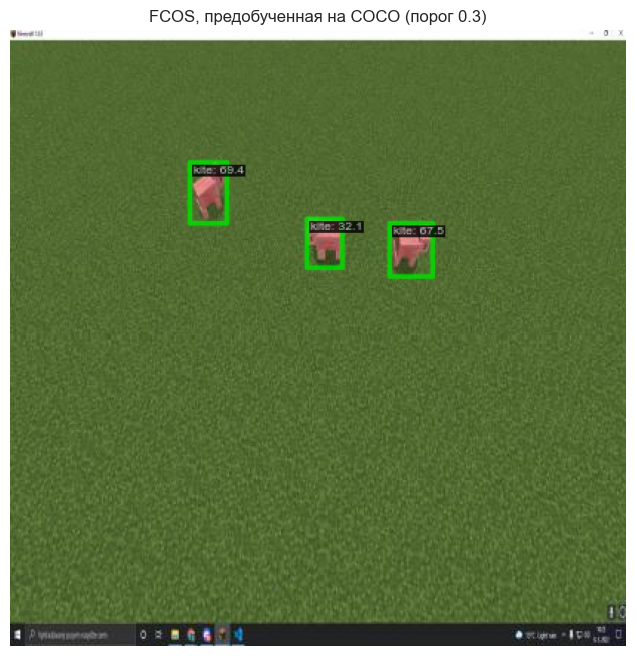

In [14]:
import os

import cv2
import torch
import matplotlib.pyplot as plt
from mmdet.apis import init_detector, inference_detector
from mmdet.visualization import DetLocalVisualizer

from constants import IMG_DIRS, INFERENCE_DIR, FCOS_CONFIG, FCOS_PRETRAINED

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TEST_IMAGE = os.path.join(IMG_DIRS['test'], 'image16_png_jpg.rf.4652c73eb379a657701b8cbe134c38fc.jpg')

# Наш конфиг + веса COCO; голове временно возвращаем 80 классов, чтобы веса совпали
fcos_coco = init_detector(FCOS_CONFIG, FCOS_PRETRAINED, palette='coco', device=device,
                          cfg_options={'model.bbox_head.num_classes': 80})
result = inference_detector(fcos_coco, TEST_IMAGE)

# Для отрисовки воспользуемся классом DetLocalVisualizer из MMDetection
image = cv2.imread(TEST_IMAGE)
visualizer = DetLocalVisualizer()
visualizer.dataset_meta = fcos_coco.dataset_meta
visualizer.add_datasample(
    name='result',
    image=image,
    data_sample=result,
    draw_gt=False,
    draw_pred=True,
    show=False,
    pred_score_thr=0.3
)
viz = visualizer.get_image()

os.makedirs(INFERENCE_DIR, exist_ok=True)
cv2.imwrite(os.path.join(INFERENCE_DIR, 'test_pretrained.jpg'), viz)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(viz, cv2.COLOR_BGR2RGB))
plt.title('FCOS, предобученная на COCO (порог 0.3)')
plt.axis('off')
plt.show()

Пайплайн работает: модель уверенно находит все три объекта, но называет их `kite` — в COCO нет класса «свинья из Minecraft», а розовые прямоугольники на зелёном фоне больше всего похожи на воздушных змеев. Это ровно та причина, по которой модель нужно дообучать.

Теперь соберём модель строго по нашему конфигу — с головой на 17 классов. MMEngine предупредит о несовпадении размеров `bbox_head.conv_cls` (80 → 17): этот слой инициализируется заново и будет обучен на этапе 4, остальные веса переносятся из чекпоинта.

In [15]:
fcos_minecraft = init_detector(FCOS_CONFIG, FCOS_PRETRAINED, device=device)

scores = inference_detector(fcos_minecraft, TEST_IMAGE).pred_instances.scores
print(f'Необученная голова: {len(scores)} кандидатов, максимальная уверенность {scores.max():.2f} '
      f'- предсказания случайные, как и ожидалось до обучения')

Loads checkpoint by local backend from path: checkpoints/fcos_r50_caffe_fpn_gn-head_1x_coco-821213aa.pth
The model and loaded state dict do not match exactly

size mismatch for bbox_head.conv_cls.weight: copying a param with shape torch.Size([80, 256, 3, 3]) from checkpoint, the shape in current model is torch.Size([17, 256, 3, 3]).
size mismatch for bbox_head.conv_cls.bias: copying a param with shape torch.Size([80]) from checkpoint, the shape in current model is torch.Size([17]).
Необученная голова: 100 кандидатов, максимальная уверенность 0.52 - предсказания случайные, как и ожидалось до обучения


### 3.3. Описание датасета для YOLO: `data.yaml`

YOLO не читает COCO JSON — ей нужны текстовые файлы разметки (их мы подготовили на этапе 2, папка `datasets/minecraft/labels/`) и «паспорт» датасета `data.yaml`. Функция `write_data_yaml` из `prepare_yolo_dataset.py` записывает его: пути относительные — от папки самого файла, обучающая выборка задана двумя папками, исходными изображениями `images/train` и аугментированными копиями `images/train_augmented`.

In [16]:
from constants import DATA_YAML, EDA_DIR
from prepare_yolo_dataset import write_data_yaml, verify_yolo_labels

data_config = write_data_yaml()

print('Содержимое data.yaml:')
with open(DATA_YAML, 'r', encoding='utf-8') as f:
    print(f.read())

Содержимое data.yaml:
train:
- images/train
- images/train_augmented
val: images/valid
test: images/test
nc: 17
names:
- bee
- chicken
- cow
- creeper
- enderman
- fox
- frog
- ghast
- goat
- llama
- pig
- sheep
- skeleton
- spider
- turtle
- wolf
- zombie



Проверим конвертацию так же, как в уроке о подготовке данных: возьмём изображение из обучающей выборки, прочитаем его `.txt`-файл, денормализуем координаты и нарисуем рамки.

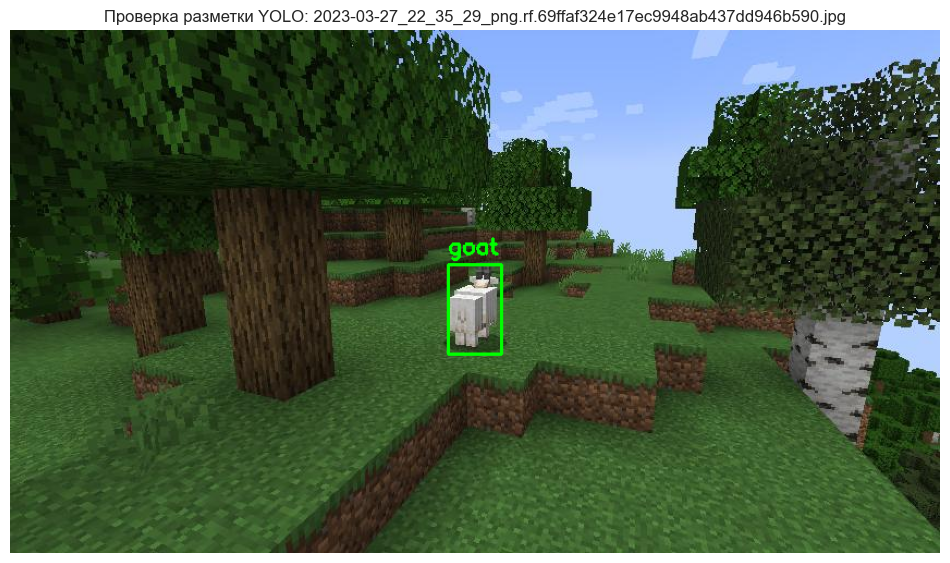

In [17]:
verify_yolo_labels(save_path=os.path.join(EDA_DIR, 'yolo_labels_check.png'))

### 3.4. Инференс предобученной YOLOv8s

Дообучать будем `yolov8s.pt` — модель среднего размера (11 M параметров), обученную на COCO. Веса скачиваются автоматически в `checkpoints/`. Проверяем её так же, как в уроках о YOLO: `model.predict()` и `results[0].plot()`, который сам рисует рамки, классы и уверенность. Результат сохраняем в `artifacts/inference/yolo_val/`.


image 1/1 F:\yandex_practicum_project_2\mmdetection\datasets\minecraft\images\test\image16_png_jpg.rf.4652c73eb379a657701b8cbe134c38fc.jpg: 640x640 1 kite, 37.3ms
Speed: 4.0ms preprocess, 37.3ms inference, 7.5ms postprocess per image at shape (1, 3, 640, 640)


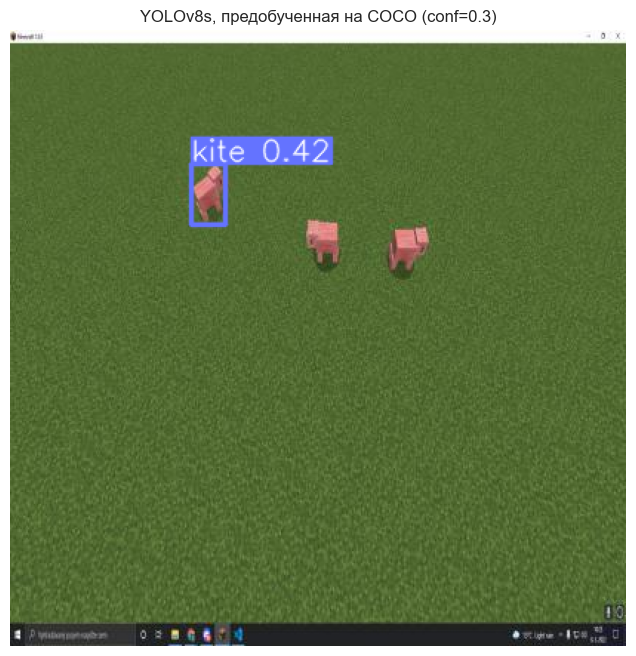

In [18]:
from ultralytics import YOLO

from constants import YOLO_PRETRAINED, YOLO_VAL_DIR

yolo_coco = YOLO(YOLO_PRETRAINED)

results = yolo_coco.predict(TEST_IMAGE, conf=0.3)
annotated_image = results[0].plot()

os.makedirs(YOLO_VAL_DIR, exist_ok=True)
cv2.imwrite(os.path.join(YOLO_VAL_DIR, 'test_pretrained.jpg'), annotated_image)

plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.title('YOLOv8s, предобученная на COCO (conf=0.3)')
plt.axis('off')
plt.show()

**Вывод по этапу 3.** Обе предобученные модели загружаются и работают. На данных Minecraft они ведут себя одинаково: находят объекты, но относят их к классам COCO (`kite`), — предобученные веса дают хорошую локализацию и признаки, а классы предстоит выучить на нашем датасете. Конфиг FCOS и `data.yaml` для YOLO готовы, можно обучать.

## Этап 4. Обучение моделей

### 4.1. Обучение FCOS

Функция `train_fcos` из `train_fcos.py` делает то же, что `tools/train.py`: читает конфиг, собирает `Runner` MMEngine и запускает `runner.train()`. В процессе обучения:

- каждые 50 итераций в лог выводятся `loss`, `loss_cls`, `loss_bbox`, `loss_centerness` и текущий `lr`;
- после каждой эпохи считаются метрики COCO на `valid` (общий mAP и AP по классам) и сохраняется чекпоинт;
- все логи, чекпоинты (`epoch_N.pth`, `best_coco_bbox_mAP_epoch_N.pth`) и файл метрик `vis_data/scalars.json` попадают в `artifacts/fcos`.

Одна эпоха — 1154 итерации (2307 изображений, батч 2); на RTX 4060 Ti это около 4–5 минут плюс минута на валидацию, всё обучение — около часа. Если обучение прервалось, его можно продолжить с последнего чекпоинта: `train_fcos(resume=True)`.

In [19]:
from constants import FCOS_CONFIG, FCOS_WORK_DIR
from train_fcos import train_fcos

fcos_runner = train_fcos(config_file=FCOS_CONFIG, work_dir=FCOS_WORK_DIR)

10/06 14:47:09 - mmengine - INFO - 
------------------------------------------------------------
System environment:
    sys.platform: win32
    Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
    CUDA available: True
    MUSA available: False
    numpy_random_seed: 1608637542
    GPU 0: NVIDIA GeForce RTX 4060 Ti
    CUDA_HOME: C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v13.0
    NVCC: Cuda compilation tools, release 13.0, V13.0.88
    MSVC: n/a, reason: fileno
    PyTorch: 2.0.0+cu118
    PyTorch compiling details: PyTorch built with:
  - C++ Version: 199711
  - MSVC 193431937
  - Intel(R) Math Kernel Library Version 2020.0.2 Product Build 20200624 for Intel(R) 64 architecture applications
  - Intel(R) MKL-DNN v2.7.3 (Git Hash 6dbeffbae1f23cbbeae17adb7b5b13f1f37c080e)
  - OpenMP 2019
  - LAPACK is enabled (usually provided by MKL)
  - CPU capability usage: AVX2
  - CUDA Runtime 11.8
  - NVCC architecture flags: -gencode;arch=compute_

**Визуализация метрик FCOS.** В MMDetection 3.x метрики обучения пишутся не в `log.json`, а в `artifacts/fcos/<время запуска>/vis_data/scalars.json` — по одной JSON-строке на запись: для итераций обучения это значения loss и lr, для валидации — метрики COCO. Разберём этот файл и построим графики.

Лог: artifacts\fcos\20261006_144526\vis_data\scalars.json
Лучший чекпоинт: artifacts\fcos\best_coco_bbox_mAP_epoch_12.pth


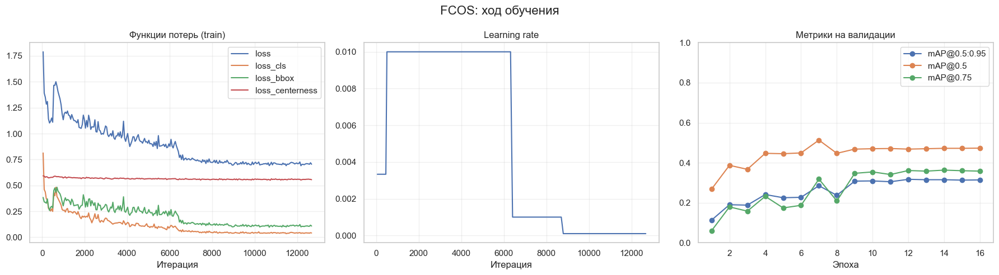

,epoch,coco/bbox_mAP,coco/bbox_mAP_50,coco/bbox_mAP_75
0,1,0.113,0.268,0.060
1,2,0.190,0.387,0.179
2,3,0.188,0.367,0.158
3,4,0.241,0.447,0.232
4,5,0.225,0.445,0.174
5,6,0.227,0.449,0.187
6,7,0.285,0.513,0.318
7,8,0.237,0.447,0.209
8,9,0.308,0.468,0.347
9,10,0.309,0.470,0.354


In [20]:
import os

from constants import FCOS_WORK_DIR
from train_fcos import find_scalars_log, load_fcos_log, plot_fcos_metrics, find_best_checkpoint

fcos_log_file = find_scalars_log(FCOS_WORK_DIR)
fcos_train_log, fcos_val_log = load_fcos_log(fcos_log_file)
print('Лог:', fcos_log_file)
print('Лучший чекпоинт:', find_best_checkpoint(FCOS_WORK_DIR))

plot_fcos_metrics(fcos_train_log, fcos_val_log,
                  save_path=os.path.join(FCOS_WORK_DIR, 'fcos_training_curves.png'))

fcos_val_log[['step', 'coco/bbox_mAP', 'coco/bbox_mAP_50', 'coco/bbox_mAP_75']].rename(columns={'step': 'epoch'})

**Выводы по обучению FCOS.** Обучение заняло 26 минут (16 эпох, 640 px, батч 4, fp16, RTX 4060 Ti).

- **Динамика loss.** Суммарный loss снизился с 1.34 до 0.71: `loss_cls` — с 0.39 до 0.04, `loss_bbox` — с 0.36 до 0.11. `loss_centerness` почти не меняется (0.583 → 0.558) — это нормально для FCOS: центральность обучается бинарной кросс-энтропией на «мягкую» цель и по построению не стремится к нулю. Заметный скачок качества виден на 9-й эпохе — сразу после снижения lr с 0.01 до 0.001 на 8-й.
- **Метрики на валидации.** mAP@0.5:0.95 вырос с 0.113 до **0.317 на 12-й эпохе** — это и есть лучший чекпоинт `best_coco_bbox_mAP_epoch_12.pth`. Эпохи 13–16 не дали ничего (0.315, 0.315, 0.313, 0.314): расписание lr из базового конфига рассчитано на 12 эпох (снижения на 8-й и 11-й), поэтому последние четыре эпохи модель училась с lr = 0.0001 и фактически стояла на месте. Вывод на будущее: увеличивать число эпох имеет смысл только вместе с растягиванием `param_scheduler`.
- **Переобучения нет:** loss на train падает плавно, mAP на валидации не деградирует, а выходит на плато.
- **Что дало повышение разрешения.** По сравнению с первым запуском (512 px, батч 2, 12 эпох) mAP@0.5:0.95 вырос с 0.273 до 0.317 (+16 %), mAP@0.5 — с 0.400 до 0.468, а AP по мелким объектам — с 0.010 до 0.030 (втрое, хотя уровень по-прежнему низкий). Это подтверждает вывод этапа 2: главный ограничитель на этом датасете — размер объектов, а не архитектура.
- **По классам** (валидация, последняя эпоха): уверенно распознаются `creeper` 0.77, `enderman` 0.57 и `spider` 0.50; средне — `cow` 0.31, `chicken` 0.31, `sheep` 0.27; `wolf` 0.23 — при двух обучающих изображениях это заслуга аугментации (в первом запуске было 0.13); слабо — `pig` 0.12 (в валидации почти все свиньи мелкие и дальние), `skeleton` 0.07 и `zombie` 0.0 (в валидации всего 8 и 2 рамки, оценка ненадёжна). Семь классов дают `nan` — их нет в валидационной выборке. По размерам объектов: AP small 0.030, medium 0.233, large 0.463.
- **Воспроизводимость.** Повторный запуск того же конфига дал те же метрики: `constants.py` фиксирует `np.random.seed(42)`, от которого MMEngine выводит собственный seed (1608637542), поэтому обучение детерминировано.

### 4.2. Обучение YOLOv8s

Функция `train_yolo` из `train_yolo.py` повторяет `train_model` из урока: проверяет `data.yaml`, загружает `yolov8s.pt` и вызывает `model.train(...)`. YOLO учится заметно быстрее FCOS, поэтому берём размер изображений 640 (как в уроках), батч 16 и 30 эпох с ранней остановкой (`patience=10`). Обучающая выборка берётся из `data.yaml` — исходные изображения плюс аугментированные копии редких классов (этап 3.3). Аугментации «на лету» — словарь `AUGMENTATIONS` из `train_yolo.py`: стандартные mosaic, HSV-сдвиги, сдвиг и масштаб, горизонтальное отражение.

Результаты Ultralytics складывает в `artifacts/yolo/yolov8s_minecraft/`: `results.csv` с метриками по эпохам, графики, матрица ошибок и веса `weights/best.pt`, `weights/last.pt`.

In [21]:
from constants import DATA_YAML
from train_yolo import train_yolo

yolo_results = train_yolo(
    data_path=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=16
)

New https://pypi.org/project/ultralytics/8.4.173 available  Update with 'pip install -U ultralytics'
Ultralytics YOLOv8.0.196  Python-3.10.11 torch-2.0.0+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 8187MiB)
engine\trainer: task=detect, mode=train, model=checkpoints/yolov8s.pt, data=F:\yandex_practicum_project_2\mmdetection\datasets\minecraft\data.yaml, epochs=30, patience=10, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=2, project=artifacts\yolo, name=yolov8s_minecraft, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=42, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, show=False, save_txt=False, save_conf=False, save_crop=False, show_labels=True, show_con

**Визуализация метрик YOLO.** Читаем `results.csv` (Ultralytics пишет его после каждой эпохи) и строим графики loss на train и val и метрик на валидации.

Лучшие веса: artifacts\yolo\yolov8s_minecraft\weights\best.pt


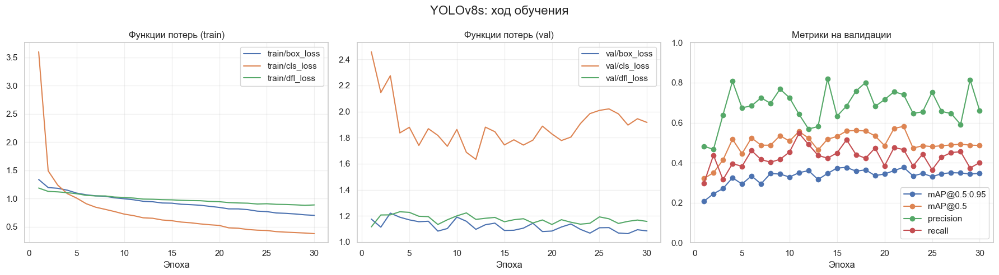

,epoch,metrics/mAP50-95(B),metrics/mAP50(B),metrics/precision(B),metrics/recall(B)
20,21,0.36050,0.57165,0.75473,0.47554
21,22,0.37713,0.58161,0.74069,0.46585
22,23,0.33410,0.47310,0.64703,0.38342
23,24,0.34655,0.48494,0.65443,0.44331
24,25,0.33028,0.48044,0.75253,0.36464
25,26,0.34505,0.48509,0.65642,0.42829
26,27,0.34995,0.48876,0.64599,0.45060
27,28,0.34891,0.49311,0.59130,0.45522
28,29,0.34334,0.48780,0.81486,0.37363
29,30,0.34688,0.48650,0.66082,0.40056


In [22]:
import os

from constants import YOLO_WORK_DIR
from train_yolo import load_yolo_results, plot_yolo_metrics, find_best_weights

yolo_log = load_yolo_results()
print('Лучшие веса:', find_best_weights())

plot_yolo_metrics(yolo_log, save_path=os.path.join(YOLO_WORK_DIR, 'yolo_training_curves.png'))

yolo_log[['epoch', 'metrics/mAP50-95(B)', 'metrics/mAP50(B)', 'metrics/precision(B)', 'metrics/recall(B)']].tail(10)

**Выводы по обучению YOLOv8s.** Обучение заняло 17 минут (30 эпох, 640 px, батч 16).

- **Динамика loss.** На train все компоненты падают монотонно: `box_loss` 1.34 → 0.70, `cls_loss` 3.60 → 0.38, `dfl_loss` 1.19 → 0.89. На валидации `box_loss` держится около 1.1 (локализация не ухудшается), а `cls_loss` достигает минимума 1.63 на 12-й эпохе и затем растёт до ≈2.0 к 25–30-й: со второй половины обучения модель начинает подстраиваться под обучающую выборку в части классификации.
- **Метрики на валидации.** mAP@0.5:0.95 вырос с 0.207 до максимума **0.377 на 22-й эпохе** (mAP@0.5 = 0.582) — этот чекпоинт сохранён как `best.pt`; на последних восьми эпохах метрика колеблется в диапазоне 0.33–0.35. Ранняя остановка (`patience=10`) не сработала: после лучшей эпохи до конца обучения оставалось меньше 10 эпох. Точность (0.65–0.82) заметно выше полноты (0.37–0.55) — модель «осторожная»: мало ложных срабатываний, но часть объектов пропускает.
- **По классам** (валидация, `best.pt`): `creeper` 0.75 (mAP@0.5 = 0.99), `enderman` 0.70, `chicken` 0.65, `cow` 0.64; слабо — `pig` 0.14, `wolf` 0.17 (полнота 0 при пороге валидации — две обучающие картинки не выучиваются даже с аугментацией), `zombie` 0.06.
- **Воспроизводимость.** Повторный запуск с `seed=42` дал полностью совпадающие значения метрик по эпохам.

### 4.3. Сравнение процесса обучения

Сведём обучение двух моделей вместе: сколько эпох потребовалось каждой, на какой эпохе был лучший результат и как метрики на валидации росли от эпохи к эпохе. Логи у фреймворков разные (`scalars.json` у MMDetection и `results.csv` у Ultralytics), поэтому функции `training_summary` и `plot_training_comparison` из `evaluate.py` приводят их к общему виду.

In [ ]:
from constants import METRICS_DIR
from evaluate import training_summary, plot_training_comparison

training_summary(fcos_val_log, yolo_log)

In [ ]:
plot_training_comparison(fcos_val_log, yolo_log,
                         save_path=os.path.join(METRICS_DIR, 'training_comparison.png'))

**Вывод по обучению двух моделей.**

- YOLOv8s идёт выше FCOS на всём протяжении обучения: уже после первой эпохи у неё mAP@0.5:0.95 = 0.207 против 0.113 у FCOS, и этот разрыв в 0.05–0.09 сохраняется до конца.
- FCOS растёт «ступеньками»: заметный скачок на 9-й эпохе, сразу после снижения learning rate, и плато начиная с 12-й. YOLO растёт плавно и шумно — её кривая колеблется даже в конце обучения, потому что mosaic каждую эпоху собирает новые комбинации изображений.
- Лучшая эпоха у FCOS — 12-я из 16 (последние четыре прошли при lr = 0.0001 и ничего не добавили), у YOLO — 22-я из 30. Обеим моделям хватило бы примерно 12 и 22 эпох соответственно.
- По времени: 26 минут у FCOS против 17 у YOLOv8s при одинаковом разрешении 640 px — YOLO и учится быстрее, и даёт более высокое качество.

## Этап 5. Инференс моделей

Загружаем лучшие веса обеих моделей: для FCOS — чекпоинт `best_coco_bbox_mAP_epoch_N.pth` из `artifacts/fcos` (через `init_detector`, как на этапе 3), для YOLO — `weights/best.pt` из папки эксперимента. Дальше обе модели используются через единый интерфейс из `detection_models.py`: `predict(model_name, model, image)` возвращает `(boxes, labels, scores)` в одном формате для обеих, а `draw_boxes` рисует рамку, класс и уверенность (функция из урока о сравнении моделей).

In [22]:
import os

import cv2
import torch
from mmdet.apis import init_detector
from ultralytics import YOLO

from constants import (FCOS_CONFIG, FCOS_WORK_DIR, IMG_DIRS, FCOS_INFERENCE_DIR, YOLO_INFERENCE_DIR,
                       VIDEO_PATH, VIDEOS_DIR)
from train_fcos import find_best_checkpoint
from train_yolo import find_best_weights
from detection_models import device, generate_visualizations, run_and_visualize

fcos_checkpoint = find_best_checkpoint(FCOS_WORK_DIR)
yolo_weights = find_best_weights()
print('FCOS:', fcos_checkpoint)
print('YOLO:', yolo_weights)

fcos_model = init_detector(FCOS_CONFIG, fcos_checkpoint, device=device)
yolo_model = YOLO(yolo_weights)

# Словарь моделей, как в уроке: по названию выбирается API инференса
models = {
    'FCOS': fcos_model,
    'YOLOv8s': yolo_model,
}

FCOS: artifacts\fcos\best_coco_bbox_mAP_epoch_12.pth
YOLO: artifacts\yolo\yolov8s_minecraft\weights\best.pt
Loads checkpoint by local backend from path: artifacts\fcos\best_coco_bbox_mAP_epoch_12.pth


### Инференс на тестовых изображениях

Прогоняем обе модели по всей тестовой выборке (155 изображений) и сохраняем картинки с рамками: `artifacts/inference/fcos` и `artifacts/inference/yolo`. Порог уверенности для отрисовки — 0.5.

In [23]:
generate_visualizations('FCOS', fcos_model, IMG_DIRS['test'], FCOS_INFERENCE_DIR, threshold=0.5)
generate_visualizations('YOLOv8s', yolo_model, IMG_DIRS['test'], YOLO_INFERENCE_DIR, threshold=0.5)

FCOS: 155 изображений с детекциями сохранены в artifacts\inference\fcos
YOLOv8s: 155 изображений с детекциями сохранены в artifacts\inference\yolo


Покажем пять тестовых изображений с разными персонажами — для каждого результаты FCOS и YOLOv8s рядом (`run_and_visualize`, как в уроке о сравнении моделей): коровы и свиньи на лугу, зомби со скелетом ночью, крипер, куры с овцой в кадре 2560×1440, эндермен.

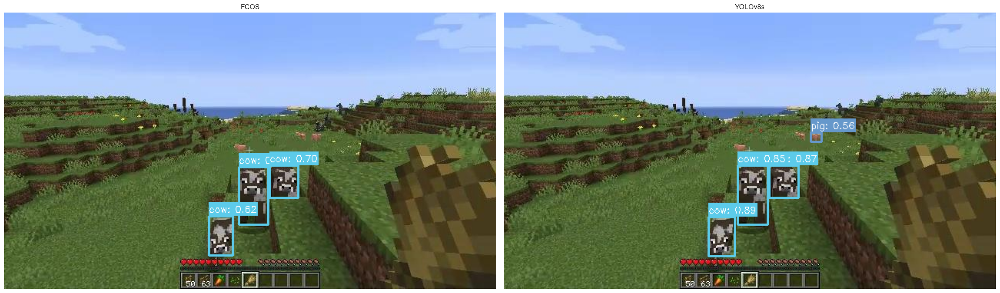

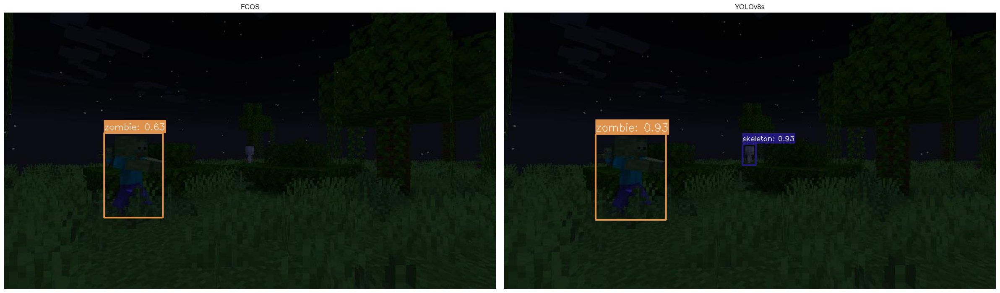

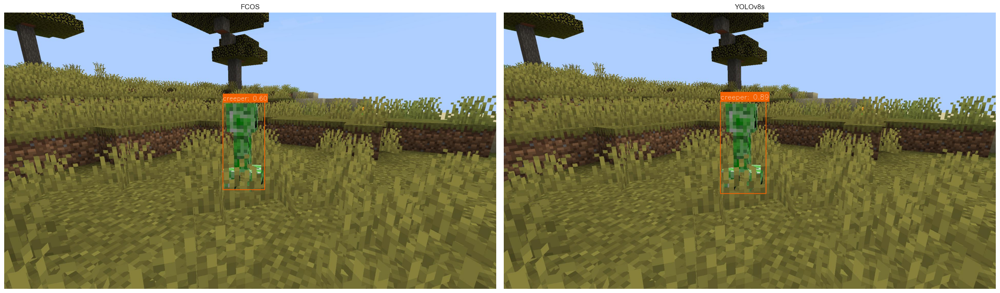

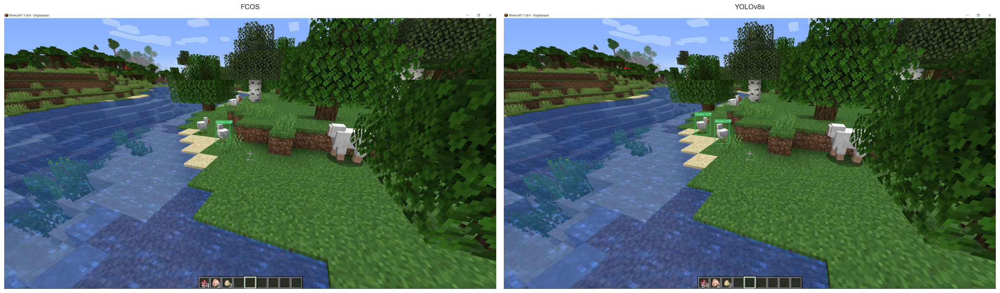

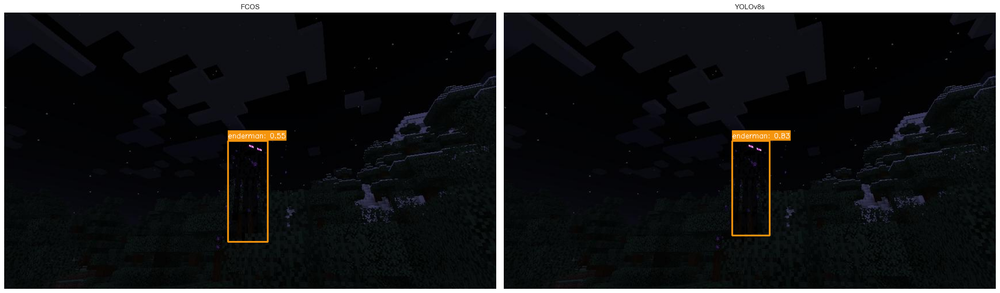

In [24]:
from constants import TEST_EXAMPLES

for image_name in TEST_EXAMPLES:
    run_and_visualize(os.path.join(IMG_DIRS['test'], image_name), models, threshold=0.5)

**Наблюдения по инференсу на изображениях.**

- **Крупные объекты** обе модели находят уверенно, рамки почти совпадают: крипер — 0.80 у FCOS и 0.83 у YOLO, эндермен ночью на тёмном фоне — 0.55 и 0.83, коровы на лугу — все три у обеих моделей (0.62–0.70 у FCOS, 0.85–0.89 у YOLO). Уверенность YOLO при одинаковых рамках систематически выше.
- **Мелкие и дальние объекты** остаются слабым местом обеих моделей: далёких свиней на том же лугу FCOS не нашла, YOLO нашла одну (0.56); на кадре 2560×1440 с курами и овцой обе отметили лишь часть кур, а овцу у кромки кадра пропустили обе.
- **Похожие силуэты и тёмные сцены:** на ночном кадре с зомби и скелетом FCOS нашла только зомби (0.63), YOLO — и зомби (0.93), и скелета (0.93). Путаницы классов при пороге 0.5 нет ни у одной модели: все ошибки — пропуски, а не ложные срабатывания.

In [25]:
from process_video import process_video, show_video_frames

process_video('FCOS', fcos_model, VIDEO_PATH, os.path.join(VIDEOS_DIR, 'fcos_inference.mp4'), confidence_threshold=0.5)
process_video('YOLOv8s', yolo_model, VIDEO_PATH, os.path.join(VIDEOS_DIR, 'yolo_inference.mp4'), confidence_threshold=0.5)

Инференс FCOS: 100%|█████████████████████████████████████████████████████████████████| 756/756 [00:43<00:00, 17.47it/s]



Обработка завершена. Результат сохранен в файл: artifacts\videos\fcos_inference.mp4


Инференс YOLOv8s: 100%|██████████████████████████████████████████████████████████████| 756/756 [00:34<00:00, 22.11it/s]


Обработка завершена. Результат сохранен в файл: artifacts\videos\yolo_inference.mp4


Сравним один и тот же кадр из двух получившихся видео.

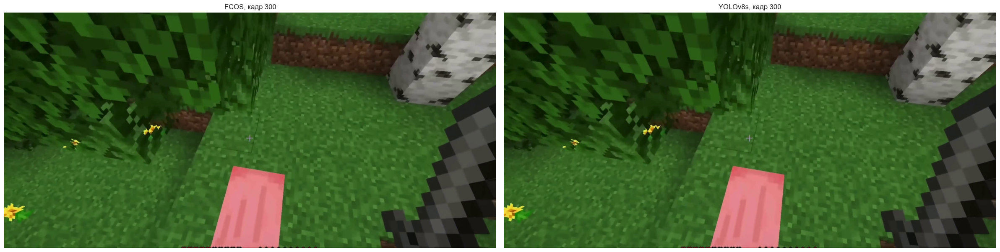

In [26]:
show_video_frames(
    {'FCOS': os.path.join(VIDEOS_DIR, 'fcos_inference.mp4'),
     'YOLOv8s': os.path.join(VIDEOS_DIR, 'yolo_inference.mp4')},
    frame_index=300
)

**Наблюдения по видео.** Основной персонаж ролика — свинья, которую камера сопровождает с разных дистанций. Обе модели ведут её стабильно от кадра к кадру: рамки не «дрожат», ложных срабатываний на траве, деревьях и элементах интерфейса нет. На дальней дистанции свинья определяется обеими моделями, но с меньшей уверенностью; овцу в конце ролика (на пляже, частично отвёрнута от камеры) при пороге 0.5 пропускают обе. Основная разница на видео — скорость обработки: 756 кадров YOLOv8s проходит заметно быстрее.

## Этап 6. Сравнение стандартных метрик

Метрики качества считаем на тестовой выборке штатными средствами каждого фреймворка (модуль `evaluate.py`):

- **FCOS** — `evaluate_fcos`: то же, что `tools/test.py` из MMDetection — `Runner` собирается по нашему конфигу с обученным чекпоинтом и вызывается `runner.test()`; `CocoMetric` считает COCO-метрики на `annotations/test/annotations.json` и печатает AP по классам;
- **YOLOv8s** — `evaluate_yolo`: `model.val(data=data.yaml, split='test')`, метрики берутся из `metrics.box` (как `evaluate_model` из урока об обучении YOLO).

Обе метрики усредняются по классам, которые есть в тестовой разметке (их 9 — см. этап 2), поэтому сравнение честное. Скорость измеряем функцией `measure_fps` из урока о сравнении моделей: один прогревочный прогон, затем 50 прогонов одного и того же изображения, FPS = число прогонов / время. Замер сквозной (предобработка, прямой проход, постобработка), на одной видеокарте, обе модели — в одном рабочем разрешении 640 px.

In [27]:
import os

import cv2
import torch
from mmdet.apis import init_detector
from ultralytics import YOLO

from constants import FCOS_CONFIG, FCOS_WORK_DIR, IMG_DIRS, METRICS_DIR, TEST_EXAMPLES
from train_fcos import find_best_checkpoint
from train_yolo import find_best_weights
from detection_models import device, measure_fps
from evaluate import evaluate_fcos, evaluate_yolo, compare_models, plot_comparison

fcos_checkpoint = find_best_checkpoint(FCOS_WORK_DIR)
yolo_weights = find_best_weights()

# Сборка Runner занимает около двух минут без вывода, затем печатается таблица COCO
fcos_metrics = evaluate_fcos(fcos_checkpoint)

09/21 16:37:41 - mmengine - INFO - 
------------------------------------------------------------
System environment:
    sys.platform: win32
    Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
    CUDA available: True
    MUSA available: False
    numpy_random_seed: 1608637542
    GPU 0: NVIDIA GeForce RTX 4060 Ti
    CUDA_HOME: C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v13.0
    NVCC: Cuda compilation tools, release 13.0, V13.0.88
    MSVC: n/a, reason: fileno
    PyTorch: 2.0.0+cu118
    PyTorch compiling details: PyTorch built with:
  - C++ Version: 199711
  - MSVC 193431937
  - Intel(R) Math Kernel Library Version 2020.0.2 Product Build 20200624 for Intel(R) 64 architecture applications
  - Intel(R) MKL-DNN v2.7.3 (Git Hash 6dbeffbae1f23cbbeae17adb7b5b13f1f37c080e)
  - OpenMP 2019
  - LAPACK is enabled (usually provided by MKL)
  - CPU capability usage: AVX2
  - CUDA Runtime 11.8
  - NVCC architecture flags: -gencode;arch=compute_

F:\yandex_practicum_project_2\clean_venv\lib\site-packages\mmengine\utils\manager.py:113: UserWarning: <class 'mmdet.visualization.local_visualizer.DetLocalVisualizer'> instance named of visualizer has been created, the method `get_instance` should not accept any other arguments
  warnings.warn(


09/21 16:37:54 - mmengine - INFO - Distributed training is not used, all SyncBatchNorm (SyncBN) layers in the model will be automatically reverted to BatchNormXd layers if they are used.
09/21 16:37:54 - mmengine - INFO - Hooks will be executed in the following order:
before_run:
(VERY_HIGH   ) RuntimeInfoHook                    
(BELOW_NORMAL) LoggerHook                         
 -------------------- 
before_train:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
(VERY_LOW    ) CheckpointHook                     
 -------------------- 
before_train_epoch:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
(NORMAL      ) DistSamplerSeedHook                
 -------------------- 
before_train_iter:
(VERY_HIGH   ) RuntimeInfoHook                    
(NORMAL      ) IterTimerHook                      
 -------------------- 
after_train_iter:
(VERY_HIGH   ) RuntimeInfoHook                

In [28]:
yolo_metrics = evaluate_yolo(yolo_weights)

Ultralytics YOLOv8.0.196  Python-3.10.11 torch-2.0.0+cu118 CUDA:0 (NVIDIA GeForce RTX 4060 Ti, 8187MiB)
Model summary (fused): 168 layers, 11132163 parameters, 0 gradients, 28.5 GFLOPs
val: Scanning F:\yandex_practicum_project_2\mmdetection\datasets\minecraft\labels\test.cache... 155 images, 0 backgroun
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 10/10 [00:01
                   all        155        351      0.861       0.75      0.798      0.558
               chicken        155         13       0.92      0.888      0.935      0.654
                   cow        155         22      0.779        0.8      0.854      0.638
               creeper        155         17      0.967      0.882      0.925      0.753
              enderman        155          2      0.891          1      0.995      0.697
                   pig        155        230      0.929      0.859      0.919      0.509
                 sheep        155        


Результаты оценки YOLO:
  mAP@0.5: 0.7982
  mAP@0.5:0.95: 0.5582
  Точность (средняя): 0.8613
  Полнота (средняя): 0.7496


In [29]:
# Загружаем обе модели (этап 6 можно запускать отдельно от этапа 5)
models = {
    'FCOS': init_detector(FCOS_CONFIG, fcos_checkpoint, device=device),
    'YOLOv8s': YOLO(yolo_weights),
}

fps_image = cv2.imread(os.path.join(IMG_DIRS['test'], TEST_EXAMPLES[0]))
fps_results = measure_fps(models, fps_image, num_runs=50)

Loads checkpoint by local backend from path: artifacts\fcos\best_coco_bbox_mAP_epoch_12.pth

==================== Результаты измерения End-to-End FPS ====================
YOLOv8s        : 109.07 FPS
FCOS           : 40.97 FPS


Таблица сравнения сохранена в artifacts\metrics\metrics_comparison.csv


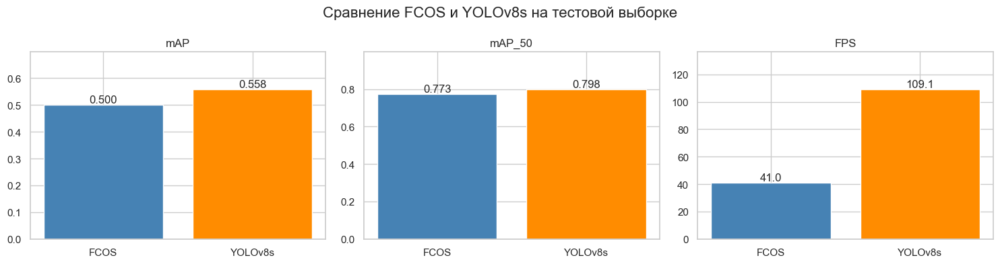

,mAP,mAP_50,FPS
model,,,
FCOS,0.5000,0.7730,40.9672
YOLOv8s,0.5582,0.7982,109.0708


In [30]:
comparison = compare_models(
    metrics={'FCOS': fcos_metrics, 'YOLOv8s': yolo_metrics},
    fps_results=fps_results,
    save_path=os.path.join(METRICS_DIR, 'metrics_comparison.csv')
)
plot_comparison(comparison, save_path=os.path.join(METRICS_DIR, 'metrics_comparison.png'))
comparison

Общий mAP усреднён по девяти классам, которые есть в тестовой разметке. Посмотрим, из чего он складывается — AP@0.5:0.95 по каждому классу у обеих моделей (`per_class_table` и `plot_per_class` из `evaluate.py`; значения берутся из той же оценки: у FCOS — из `classwise`-вывода `CocoMetric`, у YOLO — из `metrics.box.ap`).

In [ ]:
from evaluate import per_class_table, plot_per_class

class_comparison = per_class_table({'FCOS': fcos_metrics, 'YOLOv8s': yolo_metrics})
class_comparison

In [ ]:
plot_per_class(class_comparison, save_path=os.path.join(METRICS_DIR, 'per_class_comparison.png'))

**Выводы по метрикам.**

- **Качество.** На тестовой выборке YOLOv8s выше FCOS по обеим метрикам: mAP@0.5:0.95 **0.558 против 0.500** (+0.058), mAP@0.5 **0.798 против 0.773** (+0.025). Небольшой разрыв по mAP@0.5 при заметном по строгой метрике означает, что объекты находят обе модели примерно одинаково, но YOLO точнее очерчивает рамки. Тестовые значения выше валидационных (0.558 против 0.377 и 0.500 против 0.317), потому что 230 из 351 тестовых рамок — свиньи, в основном крупные, а в валидации больше мелких и редких объектов.
- **Скорость.** YOLOv8s — **110 FPS**, FCOS — **41 FPS** (сквозной замер, 50 прогонов одного изображения, обе модели в разрешении 640 px): YOLO быстрее в 2,7 раза. Исходное видео снято с 60 кадрами в секунду — в реальном времени его обрабатывает только YOLOv8s; FCOS годится для офлайн-обработки или потока до 40 кадров в секунду. Причина разрыва архитектурная: FCOS делает плотные предсказания на пяти уровнях FPN и завершает их NMS, YOLOv8s выдаёт результат за один проход с лёгкой постобработкой.
- **По классам.** YOLO лучше на семи классах из девяти, сильнее всего на `spider` (0.65 против 0.48), `enderman` (0.70 против 0.55) и `chicken` (0.65 против 0.55). FCOS выигрывает на двух ночных классах с малым числом рамок: `skeleton` (0.50 против 0.40, 4 рамки в тесте) и `zombie` (0.20 против 0.14, 3 рамки) — на таких объёмах разница в пределах шума. Лучший класс у обеих моделей — `creeper` (0.70 и 0.75), худший — `zombie`.
- **Эффект аугментации** на тесте оценить нельзя: из десяти размноженных классов в тестовой выборке есть только `sheep` (0.50 у FCOS и 0.58 у YOLO — на уровне частых классов). На валидации эффект виден по `wolf`: AP 0.23 у FCOS против 0.13 в первом запуске без аугментации.

## Этап 7. Анализ и выводы

Итоговый отчёт `artifacts/report.pdf` собирается функцией `build_report` из `report.py` тем же способом, что отчёт по дорожной обстановке в уроке об анализе трафика: класс `PDFReport(FPDF)` из `fpdf2` со шрифтами DejaVu из папки `ttf/` и методами `chapter_title`, `chapter_body`, `add_image_section`. В отчёт попадают:

1. описание проекта: данные, дисбаланс и аугментация, параметры обучения (читаются из конфига FCOS и `args.yaml` YOLO);
2. метрики качества на тесте из `metrics_comparison.csv` и вывод по ним;
3. FPS обеих моделей и вывод по скорости;
4. графики: сравнение метрик, кривые обучения FCOS и YOLOv8s;
5. примеры детекций на пяти тестовых изображениях — слева FCOS, справа YOLOv8s.

Тексты выводов задаются ниже — их нужно написать по результатам обучения (этапы 4–6).

In [ ]:
from constants import TEST_EXAMPLES
from report import build_report

quality_conclusion = (
    'YOLOv8s точнее FCOS на тестовой выборке: 0.558 против 0.500 по mAP@0.5:0.95 и 0.798 против 0.773 '
    'по mAP@0.5. Небольшой разрыв по mAP@0.5 при заметном по строгой метрике означает, что объекты '
    'находят обе модели, но YOLO точнее очерчивает рамки. YOLO лучше на семи классах из девяти, сильнее '
    'всего на spider, enderman и chicken; FCOS выигрывает на двух ночных классах с единицами рамок в '
    'тесте - skeleton и zombie. Слабое место обеих моделей - мелкие и дальние объекты: повышение '
    'разрешения FCOS с 512 до 640 px подняло её mAP на валидации с 0.273 до 0.317, но AP по мелким '
    'объектам остался на уровне 0.03.'
)
speed_conclusion = (
    'YOLOv8s работает в 2.7 раза быстрее FCOS (110 против 41 FPS на RTX 4060 Ti при одинаковом '
    'разрешении 640 px) и обучается быстрее - 17 минут против 26. Причина архитектурная: FCOS делает '
    'плотные предсказания на пяти уровнях FPN и завершает их NMS, YOLOv8s выдаёт результат за один '
    'проход с лёгкой постобработкой. При 60 кадрах в секунду у исходного видео в реальном времени '
    'работает только YOLOv8s; FCOS подходит для офлайн-обработки или потока до 40 кадров в секунду.'
)

build_report(quality_conclusion, speed_conclusion, TEST_EXAMPLES)

### Итоговые выводы

- **Качество.** YOLOv8s выиграла по обеим метрикам: на тесте 0.558 против 0.500 (mAP@0.5:0.95) и 0.798 против 0.773 (mAP@0.5), на валидации 0.377 против 0.317. Преимущество есть на семи классах из девяти; FCOS лучше только на `skeleton` и `zombie` — ночных классах, у которых в тесте 4 и 3 рамки.
- **Скорость.** 110 FPS против 41 FPS (в 2,7 раза) при одинаковом разрешении 640 px, плюс вдвое более быстрое обучение: 17 минут против 26. Для видео 60 кадров в секунду в реальном времени подходит только YOLOv8s.
- **Данные решают больше, чем архитектура.** Повышение разрешения FCOS с 512 до 640 px дало +0.044 mAP на валидации — больше, чем любая другая правка конфигурации; аугментация редких классов подняла `wolf` с 0.13 до 0.23 при двух обучающих изображениях. При этом AP по мелким объектам у FCOS остался 0.03: при 640 px 27 % объектов датасета всё ещё меньше 32 пикселей.
- **Визуальная оценка.** На тестовых изображениях и на видео рамки обеих моделей стабильны, ложных срабатываний нет; все ошибки — пропуски далёких и мелких мобов. Уверенность YOLO при одинаковых рамках систематически выше.
- **Что выбрать.** Для видеопотока и интерактивных сценариев — YOLOv8s: точнее, в 2,7 раза быстрее и проще в запуске. FCOS уместна там, где важна модульная архитектура MMDetection (замена backbone, neck или головы правкой конфига) и нет жёстких требований к скорости.
- **Что улучшить дальше.** Разрешение 800–1024 px или нарезка кадров на тайлы — против мелких объектов; стратифицированное разбиение данных (сейчас в valid и test нет 7–8 классов из 17, а `wolf` снят всего на двух изображениях); для FCOS — растянутое расписание lr, если увеличивать число эпох (в текущем запуске эпохи 13–16 прошли при lr = 0.0001 и ничего не добавили).

Краткое описание проекта и итоговая таблица — в `README.md`, подробный отчёт с графиками и примерами детекций — в `artifacts/report.pdf`.